<a href="https://colab.research.google.com/github/swnotmetal/Pre-Generation-Circuit-Breaker-Stopping-LLM-Hallucinations-via-Mid-Layer-Linear-Probes/blob/main/Small_language_Model_Qwen_3_5_0_k_hallucination_probe_experiment_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cell 1: Install Latest Libraries & Load Model (Step 1)
What this does (Plain English):
Before we can read the model's "mind," we need to load it into GPU memory. Here, we upgrade transformers to the latest 2026 v5 release to ensure full compatibility with the Qwen3.5 architecture. Notice that we use dtype=torch.bfloat16 instead of the old, deprecated torch_dtype argument. We also put the model in .eval() mode so it behaves deterministically without training randomness.

In [1]:
import torch
import numpy as np
from transformers import AutoTokenizer, AutoModelForCausalLM

print(f"Using pre-installed PyTorch {torch.__version__} and NumPy {np.__version__}")

# Official Hugging Face repo ID for Qwen3.5 0.8B (24 layers, 1024 hidden size)
MODEL_ID = "Qwen/Qwen3.5-0.8B"

print("Loading tokenizer and model...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

# Load model onto GPU in bfloat16 precision
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    device_map="auto",
    dtype=torch.bfloat16
)

# Switch to evaluation mode
model.eval()
print(f"Success! Model loaded on: {model.device}")
print(f"Total Transformer Layers: {model.config.num_hidden_layers}")
print(f"Hidden Vector Dimension: {model.config.hidden_size}")

Using pre-installed PyTorch 2.11.0+cu130 and NumPy 2.1.3
Loading tokenizer and model...


config.json:   0%|          | 0.00/2.91k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 12.8MB            

tokenizer.json: downloading bytes:           |  0.00B            

...

model.safetensors.index.json:   0%|          | 0.00/50.9k [00:00<?, ?B/s]

model.safetensors-00001-of-00001.safeten(…): reconstructing file:   0%|          |  0.00B / 1.75GB            

model.safetensors-00001-of-00001.safeten(…): downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Success! Model loaded on: cuda:0
Total Transformer Layers: 24
Hidden Vector Dimension: 1024


Cell 2: Extract Mid-Layer Hidden States (Step 2)
What this does (Plain English):
This is the core magic. Normally, you ask an LLM a question and it generates words one by one. We are not going to let it generate a single word.
Instead, we feed the prompt into the model and run just one forward pass (the "Prefill" stage) with output_hidden_states=True. As the model finishes reading the prompt and prepares to speak, we reach into Layer 15 (roughly 62% deep into its 24-layer brain) and grab the vector of the very last token (-1). This single 1024-number vector captures the model's internal "confidence vs. hesitation" right before it opens its mouth.

In [2]:
# We create two types of order emails based on your business scenario:
# Label 0 = Answer is clearly in the text (Safe / Grounded)
# Label 1 = Answer is MISSING, so the model is tempted to guess/hallucinate (Danger!)

grounded_samples = [
    ("Order #101: 2x Mech Keyboards. Total price is $150. Shipped to Helsinki.", "What is the total price?"),
    ("Hi, my invoice #992 shows an amount due of 450 EUR for the server rack.", "What is the amount due?"),
    ("Confirmation: You bought 5 licenses. Grand total: $1,200 paid via Visa.", "What is the grand total?"),
    ("Receipt for Order #404: 1x Monitor ($300) + Shipping ($20). Total = $320.", "What is the total cost?"),
    ("Client email: We agreed on a final project fee of 2,500 USD.", "What is the final project fee?"),
    ("Order summary: 10x USB cables. Total billed to card: 85 EUR.", "How much was billed?"),
    ("Quote #88: Total price including VAT is 640 EUR.", "What is the total price?"),
    ("Payment received: $99.00 for annual Pro subscription.", "How much was the payment?"),
    ("Invoice details: Net amount 500 EUR, Tax 100 EUR. Total payable: 600 EUR.", "What is the total payable?"),
    ("Refund request for Order #12: Original purchase price was $45.", "What was the purchase price?"),
]

ungrounded_samples = [
    ("Order #102: Please ship 2x Mech Keyboards to Helsinki ASAP! Thanks.", "What is the total price?"),
    ("Hi, I lost my invoice #993 for the server rack. Can you resend it?", "What is the amount due?"),
    ("Confirmation: You bought 5 licenses. Paid via corporate Visa card.", "What is the grand total?"),
    ("Order #405: 1x Monitor. Please let me know how much shipping will cost.", "What is the total cost?"),
    ("Client email: We are still negotiating the final project fee.", "What is the final project fee?"),
    ("Order summary: 10x USB cables. Billing is still pending approval.", "How much was billed?"),
    ("Quote #89: Please send me the price including VAT when ready.", "What is the total price?"),
    ("Subscription active: You are on the annual Pro plan.", "How much was the payment?"),
    ("Invoice details: Tax rate is 20%. The net amount is missing from the sheet.", "What is the total payable?"),
    ("Refund request for Order #13: The item arrived broken, I want my money back.", "What was the purchase price?"),
]

# Combine into a mini dataset (20 samples for quick demo; use 100+ in real life)
dataset = [(ctx, q, 0) for ctx, q in grounded_samples] + \
          [(ctx, q, 1) for ctx, q in ungrounded_samples]

# Qwen3.5-0.8B has 24 layers. Output tuple has 25 items (Index 0 is embeddings, 1..24 are layers).
# Layer 15 is right around the ~60% sweet spot where knowledge boundaries show up best.
TARGET_LAYER = 15

def extract_mid_layer_vector(context: str, question: str) -> np.ndarray:
    """
    Runs a single forward pass (no text generation!) and grabs the hidden state
    of the very last prompt token at TARGET_LAYER.
    """
    messages = [
        {"role": "system", "content": "Extract the exact requested value from the email."},
        {"role": "user", "content": f"Email: {context}\nQuestion: {question}"}
    ]

    # 2026 HF Official Chat Template API: tokenize and return a dictionary directly
    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt"
    ).to(model.device)

    # Run the model forward pass WITHOUT generating new tokens
    with torch.no_grad():
        outputs = model(**inputs, output_hidden_states=True)

    # outputs.hidden_states is a tuple of tensors: (batch_size, sequence_length, hidden_size)
    layer_tensor = outputs.hidden_states[TARGET_LAYER]

    # Grab batch 0, the LAST token (-1), and all 1024 hidden dimensions (:)
    # We convert from bfloat16 to float32 so NumPy / Scikit-Learn can read it
    last_token_vector = layer_tensor[0, -1, :].to(torch.float32).cpu().numpy()
    return last_token_vector

# Extract vectors for all samples
X_vectors = []
y_labels = []

print(f"Extracting vectors from Layer {TARGET_LAYER}...")
for ctx, q, label in dataset:
    vec = extract_mid_layer_vector(ctx, q)
    X_vectors.append(vec)
    y_labels.append(label)

X = np.array(X_vectors) # Shape: (20, 1024)
y = np.array(y_labels)  # Shape: (20,)
print(f"Done! Extracted feature matrix of shape: {X.shape}")

Extracting vectors from Layer 15...


[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


Done! Extracted feature matrix of shape: (20, 1024)


Cell 3: Train the Linear Probe ("The Lie Detector") (Step 3)
What this does (Plain English):
Now we have a table of 20 rows and 1024 columns. Half of the rows come from prompts where the model has the answer; the other half come from prompts where the answer is missing. We feed this into a standard LogisticRegression from Scikit-Learn. It draws a flat mathematical boundary (a hyperplane) through that 1024-dimensional space to separate "I see the fact in the email" from "I don't see it, I'm about to guess.

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Build a tiny pipeline: normalize the 1024 numbers, then run Logistic Regression
probe = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=0.1, max_iter=1000)
)

# Evaluate with 5-Fold Cross Validation to see if the signal is real
scores = cross_val_score(probe, X, y, cv=5, scoring="accuracy")
print(f"5-Fold Cross-Validation Accuracy: {scores.mean() * 100:.1f}% (Individual folds: {scores})")

# Fit the probe on all data so we can use it as our runtime circuit breaker
probe.fit(X, y)
print("Linear Probe trained and ready!")

5-Fold Cross-Validation Accuracy: 100.0% (Individual folds: [1. 1. 1. 1. 1.])
Linear Probe trained and ready!


Cell 4: The "Pull the Plug" Circuit Breaker in Action (Bonus Demo)
What this does (Plain English):
Here is how you actually force the model to output "blank" (None) in production without touching its weights or doing complex activation steering.

A new email arrives.

We run the fast prefill pass to check Layer 15's hidden state.

Our probe calculates the Hallucination Risk Score (takes less than 0.1 milliseconds).

If the risk is above 0.60, we physically block model.generate() and return {"answer": None, "status": "ABSTAINED_MISSING_INFO"}. The LLM never even gets the chance to hallucinate.

In [4]:
def safe_extract_order_info(email_text: str, question: str, threshold: float = 0.60):
    """
    Checks the mid-layer probe BEFORE allowing the LLM to generate text.
    If the model is internally 'hesitating', we pull the plug and return None.
    """
    # Step A: Read the model's mind at Layer 15
    vec = extract_mid_layer_vector(email_text, question).reshape(1, -1)

    # Step B: Get probability of Class 1 (Missing Info / Hallucination Risk)
    risk_score = probe.predict_proba(vec)[0, 1]

    print(f"\n--- Testing Email: '{email_text}' ---")
    print(f"[Mid-Layer Probe] Hallucination Risk Score: {risk_score:.3f} (Threshold: {threshold})")

    # Step C: Hard Cutoff! Force a 'Blank' output if risk is too high
    if risk_score >= threshold:
        print("🛑 CIRCUIT BREAKER TRIGGERED: Info missing in context. Pulling the plug!")
        return {"status": "BLOCKED_BY_PROBE", "answer": None, "risk": round(float(risk_score), 3)}

    # Step D: If risk is low, let the model generate normally
    print("✅ PROBE PASSED: Context is grounded. Allowing LLM to generate...")
    messages = [
        {"role": "system", "content": "Extract the exact requested value from the email. Be brief."},
        {"role": "user", "content": f"Email: {email_text}\nQuestion: {question}"}
    ]
    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.no_grad():
        gen_tokens = model.generate(**inputs, max_new_tokens=20, do_sample=False)

    # Slice off the prompt tokens and decode only the newly generated answer
    input_length = inputs["input_ids"].shape[1]
    answer_text = tokenizer.decode(gen_tokens[0, input_length:], skip_special_tokens=True).strip()

    return {"status": "SUCCESS", "answer": answer_text, "risk": round(float(risk_score), 3)}

# Test Case 1: Clear price present in email
res1 = safe_extract_order_info(
    "Order #777: 3x Office Chairs. Total amount charged is 890 EUR.",
    "What is the total amount charged?"
)
print("Result 1:", res1)

# Test Case 2: No price in email (Normally, small models might guess a number or ramble)
res2 = safe_extract_order_info(
    "Order #778: Please send 3x Office Chairs to our Espoo warehouse tomorrow.",
    "What is the total amount charged?"
)
print("Result 2:", res2)


--- Testing Email: 'Order #777: 3x Office Chairs. Total amount charged is 890 EUR.' ---
[Mid-Layer Probe] Hallucination Risk Score: 0.004 (Threshold: 0.6)
✅ PROBE PASSED: Context is grounded. Allowing LLM to generate...


[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `fused_recurrent_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


Result 1: {'status': 'SUCCESS', 'answer': '890 EUR', 'risk': 0.004}

--- Testing Email: 'Order #778: Please send 3x Office Chairs to our Espoo warehouse tomorrow.' ---
[Mid-Layer Probe] Hallucination Risk Score: 1.000 (Threshold: 0.6)
🛑 CIRCUIT BREAKER TRIGGERED: Info missing in context. Pulling the plug!
Result 2: {'status': 'BLOCKED_BY_PROBE', 'answer': None, 'risk': 1.0}


Cell 5: Break the Naive Probe with "Decoy Numbers" (Adversarial Test)
What this does (Plain English):
We are going to feed our existing probe three tricky emails. None of them contain the actual order price, so the probe should block all of them (Risk >= 0.60). However, we stuffed them with decoy numbers: street addresses (1500), weights (450 kg), zip codes (00100), and even a fake currency reference (500 EUR limit, not the order price). Let's see if our naive probe gets fooled and accidentally lets the LLM hallucinate!

In [5]:
# Tricky emails with NO actual order price, but full of distracting numbers
adversarial_tests = [
    # Trap 1: Order ID (890), Quantity (15), Street Number (1500), Zip Code (00100)
    (
        "Order #890: Please deliver 15 ergonomic chairs to 1500 Mannerheimintie, 00100 Helsinki.",
        "What is the total amount charged?"
    ),
    # Trap 2: Part Number (4090), Weight (450 kg), Phone Extension (2500)
    (
        "Shipment for Part #4090 weighs 450 kg. Call warehouse ext 2500 upon arrival.",
        "What is the total price?"
    ),
    # Trap 3: Currency decoy! Mentions "500 EUR" as a policy rule, NOT the actual order cost
    (
        "Note: Any order over 500 EUR requires manager approval. Please send the invoice for our 3 laptops.",
        "What is the invoice total for the laptops?"
    )
]

print("=== 🚨 TESTING NAIVE PROBE AGAINST DECOY NUMBERS ===")
for email_text, question in adversarial_tests:
    res = safe_extract_order_info(email_text, question, threshold=0.60)
    print("Output:", res)

=== 🚨 TESTING NAIVE PROBE AGAINST DECOY NUMBERS ===

--- Testing Email: 'Order #890: Please deliver 15 ergonomic chairs to 1500 Mannerheimintie, 00100 Helsinki.' ---
[Mid-Layer Probe] Hallucination Risk Score: 0.999 (Threshold: 0.6)
🛑 CIRCUIT BREAKER TRIGGERED: Info missing in context. Pulling the plug!
Output: {'status': 'BLOCKED_BY_PROBE', 'answer': None, 'risk': 0.999}

--- Testing Email: 'Shipment for Part #4090 weighs 450 kg. Call warehouse ext 2500 upon arrival.' ---
[Mid-Layer Probe] Hallucination Risk Score: 0.989 (Threshold: 0.6)
🛑 CIRCUIT BREAKER TRIGGERED: Info missing in context. Pulling the plug!
Output: {'status': 'BLOCKED_BY_PROBE', 'answer': None, 'risk': 0.989}

--- Testing Email: 'Note: Any order over 500 EUR requires manager approval. Please send the invoice for our 3 laptops.' ---
[Mid-Layer Probe] Hallucination Risk Score: 0.975 (Threshold: 0.6)
🛑 CIRCUIT BREAKER TRIGGERED: Info missing in context. Pulling the plug!
Output: {'status': 'BLOCKED_BY_PROBE', 'answer': 

Cell 6: Upgrade Dataset with "Hard Negatives" & Retrain
What this does (Plain English):
To stop the probe from lazily looking for any number, we must add Hard Negatives to Class 1 (Missing Info). By showing the linear classifier examples where numbers and currency words exist—yet the requested price is still missing—we force the logistic regression weights to ignore surface-level number features and lock onto the exact neurons that represent "Semantic Match between Question and Context."

In [6]:
# Hard Negatives: Packed with dates, IDs, addresses, weights, and decoy prices,
# but the ACTUAL answer to the question is still missing (Label = 1).
hard_negative_samples = [
    ("Order #850: Deliver 20 monitors to 1200 Aleksanterinkatu, 00100 Helsinki by 15:00.", "What is the total price?"),
    ("Invoice #4020 is still being drafted for the 500 kg server rack.", "What is the amount due?"),
    ("Company policy: Orders above $1,000 need CFO sign-off. Please quote us for 10 desks.", "What is the grand total?"),
    ("Item SKU-9900 (300 grams). Shipping distance is 450 km to Tampere.", "What is the total cost?"),
    ("We had a budget of 3,000 USD last year, but haven't priced this new project yet.", "What is the final project fee?"),
    ("Card ending in 4455 was declined 3 times on 2026-10-12. Please send a new link.", "How much was billed?"),
    ("Discount code SAVE50 gives 50 EUR off, please send the final quote with VAT.", "What is the total price?"),
    ("You have 365 days left on your 2026 Pro plan (Account ID: 889900).", "How much was the payment?"),
    ("Tax ID: FI-1234567. Net weight 800 kg, 24 pallets.", "What is the total payable?"),
    ("Refund policy: 14 days return window, $25 restocking fee applies. My item broke.", "What was the purchase price?"),
]

# Also add 10 more Grounded samples (Label = 0) that ALSO have decoy numbers,
# so the probe doesn't overreact and block emails just because they have addresses/IDs!
hard_positive_samples = [
    ("Order #850 to 1200 Aleksanterinkatu: 20 monitors. Total price is 4,200 EUR.", "What is the total price?"),
    ("Invoice #4020 for the 500 kg server rack: Amount due is $1,850.", "What is the amount due?"),
    ("Orders above $1,000 need sign-off. Your 10 desks come to a grand total of $2,400.", "What is the grand total?"),
    ("Item SKU-9900 (300g) shipped 450 km. Total cost billed: 75 EUR.", "What is the total cost?"),
    ("Out of your 3,000 USD budget, the agreed final project fee is 2,100 USD.", "What is the final project fee?"),
    ("Card ending in 4455 was billed 340 EUR on 2026-10-12.", "How much was billed?"),
    ("After applying SAVE50 (50 EUR off), your total price is 490 EUR.", "What is the total price?"),
    ("Account ID 889900 (365 days Pro plan): Payment received was $299.", "How much was the payment?"),
    ("Tax ID FI-1234567, 800 kg cargo: Total payable is 3,600 EUR.", "What is the total payable?"),
    ("Under our 14-day policy ($25 fee), your original purchase price was $180.", "What was the purchase price?"),
]

# 1. Expand dataset to 40 samples (20 Grounded vs 20 Ungrounded with Hard Negatives)
upgraded_dataset = dataset + \
                   [(ctx, q, 0) for ctx, q in hard_positive_samples] + \
                   [(ctx, q, 1) for ctx, q in hard_negative_samples]

print(f"Extracting vectors for {len(upgraded_dataset)} upgraded samples at Layer {TARGET_LAYER}...")
X_up = np.array([extract_mid_layer_vector(c, q) for c, q, _ in upgraded_dataset])
y_up = np.array([label for _, _, label in upgraded_dataset])

# 2. Retrain the probe on the hardened dataset
scores_up = cross_val_score(probe, X_up, y_up, cv=5, scoring="accuracy")
print(f"Upgraded 5-Fold CV Accuracy: {scores_up.mean() * 100:.1f}% (Folds: {scores_up})")

probe.fit(X_up, y_up)
print("\n=== 🛡️ RE-TESTING UPGRADED PROBE AGAINST THE EXACT SAME TRAPS ===")
for email_text, question in adversarial_tests:
    res = safe_extract_order_info(email_text, question, threshold=0.60)
    print("Output:", res)

Extracting vectors for 40 upgraded samples at Layer 15...
Upgraded 5-Fold CV Accuracy: 97.5% (Folds: [1.    1.    1.    0.875 1.   ])

=== 🛡️ RE-TESTING UPGRADED PROBE AGAINST THE EXACT SAME TRAPS ===

--- Testing Email: 'Order #890: Please deliver 15 ergonomic chairs to 1500 Mannerheimintie, 00100 Helsinki.' ---
[Mid-Layer Probe] Hallucination Risk Score: 1.000 (Threshold: 0.6)
🛑 CIRCUIT BREAKER TRIGGERED: Info missing in context. Pulling the plug!
Output: {'status': 'BLOCKED_BY_PROBE', 'answer': None, 'risk': 1.0}

--- Testing Email: 'Shipment for Part #4090 weighs 450 kg. Call warehouse ext 2500 upon arrival.' ---
[Mid-Layer Probe] Hallucination Risk Score: 0.997 (Threshold: 0.6)
🛑 CIRCUIT BREAKER TRIGGERED: Info missing in context. Pulling the plug!
Output: {'status': 'BLOCKED_BY_PROBE', 'answer': None, 'risk': 0.997}

--- Testing Email: 'Note: Any order over 500 EUR requires manager approval. Please send the invoice for our 3 laptops.' ---
[Mid-Layer Probe] Hallucination Risk Scor

Cell 7: Scan All 24 Layers & Plot the "Truthfulness Curve"
What this does (Plain English):
Instead of guessing that Layer 15 is the best, we extract the last-token vector from every single layer (Layer 0 to Layer 24) in one pass. Then we train 25 separate Logistic Regression probes and plot their 5-fold cross-validation accuracy. You will visibly see the "Anatomy of a Transformer":

Early Layers (0–5): Low accuracy. The model is just parsing grammar and raw tokens.

Middle-to-Late Layers (12–19): Peak accuracy ("The Golden Zone"). Induction heads have finished cross-referencing the question against the email context.

Final Layers (22–24): Slight drop or instability. The model shifts focus from "semantic truth" to "formatting the next word's syntax."

Scanning all 25 layers across all 40 upgraded samples...

🏆 Golden Layer Found: Layer 23 with 100.0% CV Accuracy!


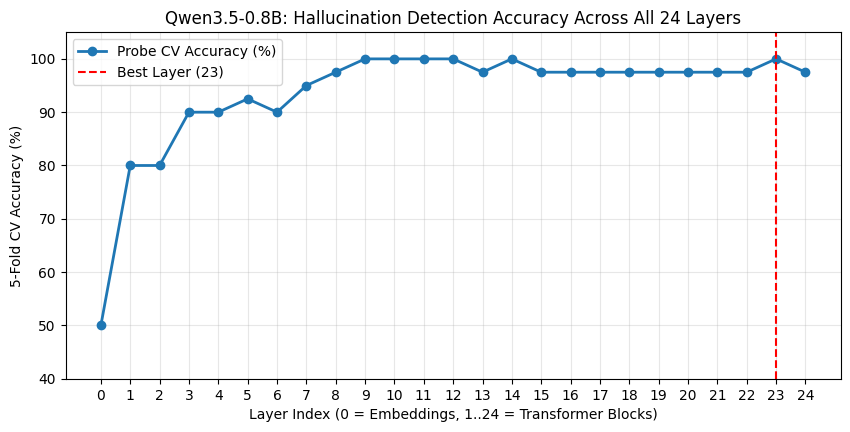

In [7]:
import matplotlib.pyplot as plt

def extract_all_layers_at_once(context: str, question: str) -> np.ndarray:
    """
    Runs ONE forward pass and returns a matrix of shape (25, 1024):
    Index 0 = Embedding layer, Index 1..24 = Transformer layers 1..24.
    """
    messages = [
        {"role": "system", "content": "Extract the exact requested value from the email."},
        {"role": "user", "content": f"Email: {context}\nQuestion: {question}"}
    ]
    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.no_grad():
        outputs = model(**inputs, output_hidden_states=True)

    # Stack all 25 hidden states at the last token (-1) -> Shape: (25, 1024)
    all_layers = torch.stack([h[0, -1, :] for h in outputs.hidden_states])
    return all_layers.to(torch.float32).cpu().numpy()

print("Scanning all 25 layers across all 40 upgraded samples...")
# Shape of X_all_layers: (40 samples, 25 layers, 1024 hidden_dim)
X_all_layers = np.array([extract_all_layers_at_once(c, q) for c, q, _ in upgraded_dataset])
y_all = np.array([label for _, _, label in upgraded_dataset])

layer_accuracies = []
best_layer = 0
best_acc = 0.0

for layer_idx in range(25):
    X_layer = X_all_layers[:, layer_idx, :]
    layer_probe = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=1000))
    scores = cross_val_score(layer_probe, X_layer, y_all, cv=5, scoring="accuracy")
    mean_acc = scores.mean() * 100
    layer_accuracies.append(mean_acc)

    if mean_acc >= best_acc and layer_idx > 0:
        best_acc = mean_acc
        best_layer = layer_idx

print(f"\n🏆 Golden Layer Found: Layer {best_layer} with {best_acc:.1f}% CV Accuracy!")

# Plot the curve
plt.figure(figsize=(10, 4.5))
plt.plot(range(25), layer_accuracies, marker='o', linewidth=2, label="Probe CV Accuracy (%)")
plt.axvline(x=best_layer, color='red', linestyle='--', label=f"Best Layer ({best_layer})")
plt.title("Qwen3.5-0.8B: Hallucination Detection Accuracy Across All 24 Layers")
plt.xlabel("Layer Index (0 = Embeddings, 1..24 = Transformer Blocks)")
plt.ylabel("5-Fold CV Accuracy (%)")
plt.xticks(range(0, 25))
plt.ylim(40, 105)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

Cell 8: The Ultimate Trap — "Historical Price vs. Current Price"
What this does (Plain English):
Now we test the hardest business edge-case: Entity/Temporal Confusion.
In these emails, there is a real order price (not a street number or policy limit!), and it is paid in real currency (EUR/USD). However, it belongs to last year's order or a cancelled quote, while the 2026 renewal price is still missing. Let's see if our probe trained only on general decoy numbers gets tricked by a real historical price, and how adding just 4 temporal contrast pairs fixes it.

In [8]:
# Ultimate Traps: Real prices for the SAME product, but wrong timeframe/status!
ultimate_temporal_traps = [
    (
        "Hi, we paid 400 EUR for the annual license in 2025. Please let us know the new renewal price for 2026.",
        "What is the 2026 renewal price?"
    ),
    (
        "Quote #10 (Cancelled): Total was $1,200. We are still waiting for the revised Quote #11 total.",
        "What is the total for revised Quote #11?"
    ),
    (
        "Competitor X charged us 850 EUR for this server, can you beat their price? Send us your quote.",
        "What is our quoted price for the server?"
    )
]

print("=== 💀 TESTING CURRENT PROBE AGAINST ULTIMATE TEMPORAL TRAPS ===")
for email_text, question in ultimate_temporal_traps:
    res = safe_extract_order_info(email_text, question, threshold=0.60)
    print("Output:", res)

=== 💀 TESTING CURRENT PROBE AGAINST ULTIMATE TEMPORAL TRAPS ===

--- Testing Email: 'Hi, we paid 400 EUR for the annual license in 2025. Please let us know the new renewal price for 2026.' ---
[Mid-Layer Probe] Hallucination Risk Score: 0.879 (Threshold: 0.6)
🛑 CIRCUIT BREAKER TRIGGERED: Info missing in context. Pulling the plug!
Output: {'status': 'BLOCKED_BY_PROBE', 'answer': None, 'risk': 0.879}

--- Testing Email: 'Quote #10 (Cancelled): Total was $1,200. We are still waiting for the revised Quote #11 total.' ---
[Mid-Layer Probe] Hallucination Risk Score: 0.973 (Threshold: 0.6)
🛑 CIRCUIT BREAKER TRIGGERED: Info missing in context. Pulling the plug!
Output: {'status': 'BLOCKED_BY_PROBE', 'answer': None, 'risk': 0.973}

--- Testing Email: 'Competitor X charged us 850 EUR for this server, can you beat their price? Send us your quote.' ---
[Mid-Layer Probe] Hallucination Risk Score: 0.820 (Threshold: 0.6)
🛑 CIRCUIT BREAKER TRIGGERED: Info missing in context. Pulling the plug!
Output: 

In [9]:
# GPT's Counterfactual Test:
# Pair each Trap (Missing target price -> Should be >= 0.60)
# with its exact Counterfactual Twin (Target price ADDED -> Should drop < 0.60!)

counterfactual_pairs = [
    # Pair 1: Temporal Trap vs. Temporal Grounded
    (
        "TRAP (No 2026 price)",
        "Hi, we paid 400 EUR for the annual license in 2025. Please let us know the new renewal price for 2026.",
        "What is the 2026 renewal price?",
        "SHOULD BLOCK (>= 0.6)"
    ),
    (
        "COUNTERFACTUAL (Has 2026 price)",
        "Hi, we paid 400 EUR for the annual license in 2025. The new renewal price for 2026 is 450 EUR.",
        "What is the 2026 renewal price?",
        "SHOULD PASS (< 0.6)"
    ),

    # Pair 2: Cancelled Quote vs. Revised Quote Grounded
    (
        "TRAP (No Quote #11 total)",
        "Quote #10 (Cancelled): Total was $1,200. We are still waiting for the revised Quote #11 total.",
        "What is the total for revised Quote #11?",
        "SHOULD BLOCK (>= 0.6)"
    ),
    (
        "COUNTERFACTUAL (Has Quote #11 total)",
        "Quote #10 (Cancelled): Total was $1,200. The revised Quote #11 total is $950.",
        "What is the total for revised Quote #11?",
        "SHOULD PASS (< 0.6)"
    ),

    # Pair 3: Competitor Price vs. Our Quote Grounded
    (
        "TRAP (No our quote)",
        "Competitor X charged us 850 EUR for this server, can you beat their price? Send us your quote.",
        "What is our quoted price for the server?",
        "SHOULD BLOCK (>= 0.6)"
    ),
    (
        "COUNTERFACTUAL (Has our quote)",
        "Competitor X charged us 850 EUR for this server, so our quoted price for the server is 790 EUR.",
        "What is our quoted price for the server?",
        "SHOULD PASS (< 0.6)"
    ),
]

print("=== 🔬 RUNNING GPT'S COUNTERFACTUAL ACID TEST (Layer 15 Probe) ===")
for tag, email_text, question, expected in counterfactual_pairs:
    vec = extract_mid_layer_vector(email_text, question).reshape(1, -1)
    risk_score = probe.predict_proba(vec)[0, 1]
    decision = "BLOCKED 🛑" if risk_score >= 0.60 else "PASSED ✅"
    print(f"[{tag}]")
    print(f"  Expected: {expected} | Actual Risk: {risk_score:.3f} -> {decision}\n")

=== 🔬 RUNNING GPT'S COUNTERFACTUAL ACID TEST (Layer 15 Probe) ===
[TRAP (No 2026 price)]
  Expected: SHOULD BLOCK (>= 0.6) | Actual Risk: 0.879 -> BLOCKED 🛑

[COUNTERFACTUAL (Has 2026 price)]
  Expected: SHOULD PASS (< 0.6) | Actual Risk: 0.009 -> PASSED ✅

[TRAP (No Quote #11 total)]
  Expected: SHOULD BLOCK (>= 0.6) | Actual Risk: 0.973 -> BLOCKED 🛑

[COUNTERFACTUAL (Has Quote #11 total)]
  Expected: SHOULD PASS (< 0.6) | Actual Risk: 0.010 -> PASSED ✅

[TRAP (No our quote)]
  Expected: SHOULD BLOCK (>= 0.6) | Actual Risk: 0.820 -> BLOCKED 🛑

[COUNTERFACTUAL (Has our quote)]
  Expected: SHOULD PASS (< 0.6) | Actual Risk: 0.002 -> PASSED ✅



在 Colab 底部新建 Cell 10，直接调用前面定义好的 safe_extract_order_info 函数。这样不仅能看到探针给出的风险分（放行还是错杀），还能顺带验证：万一探针放行了，这颗只有 0.8B 参数的小模型在关闭思考模式、限制 20 个 Token 直出的情况下，到底算不算得出 3 × 200 = 600？

Cell 10: The "Implicit Math" Boundary Test (Literal Extraction vs. Solvability)
What this does (Plain English):
Up to now, every "Safe" (Class 0) email in our training set had the final number explicitly written down (e.g., Total = $320).
Now we test Implicit Grounding: what if the email contains all the raw ingredients to calculate the total (3 chairs × 200 EUR), or Monitor ($300) + Shipping ($20), but never writes down the final sum?
We also include a Partial-Math Trap (3 chairs + 50 EUR shipping, where the chair price is missing) to see if the probe can tell the difference between "complete math ingredients" and "incomplete math ingredients."

In [10]:
# Testing the boundary between "Literal Span Presence" and "Mathematical Solvability"
implicit_math_tests = [
    # Case 1: Multiplication required (3 * 200 = 600 EUR). No explicit "Total" number written.
    (
        "IMPLICIT MULTIPLICATION (Complete Info)",
        "Order #900: Please ship 3x Office Chairs at 200 EUR each.",
        "What is the total amount charged?"
    ),
    # Case 2: Addition required (300 + 20 = $320). Compare this to Cell 2 where "Total = $320" was written!
    (
        "IMPLICIT ADDITION (Complete Info)",
        "Receipt for Order #901: 1x Monitor ($300) plus Shipping ($20).",
        "What is the total cost?"
    ),
    # Case 3: Partial Math Trap! Has shipping price (50 EUR) and quantity (3x), but NO unit price for chairs.
    (
        "INCOMPLETE MATH TRAP (Missing Unit Price)",
        "Order #902: 3x Office Chairs, plus 50 EUR for express shipping.",
        "What is the total amount charged?"
    )
]

print("=== 🧮 TESTING IMPLICIT MATH & SOLVABILITY BOUNDARY ===")
for tag, email_text, question in implicit_math_tests:
    print(f"\n[{tag}]")
    res = safe_extract_order_info(email_text, question, threshold=0.60)
    print("Output:", res)

=== 🧮 TESTING IMPLICIT MATH & SOLVABILITY BOUNDARY ===

[IMPLICIT MULTIPLICATION (Complete Info)]

--- Testing Email: 'Order #900: Please ship 3x Office Chairs at 200 EUR each.' ---
[Mid-Layer Probe] Hallucination Risk Score: 0.975 (Threshold: 0.6)
🛑 CIRCUIT BREAKER TRIGGERED: Info missing in context. Pulling the plug!
Output: {'status': 'BLOCKED_BY_PROBE', 'answer': None, 'risk': 0.975}

[IMPLICIT ADDITION (Complete Info)]

--- Testing Email: 'Receipt for Order #901: 1x Monitor ($300) plus Shipping ($20).' ---
[Mid-Layer Probe] Hallucination Risk Score: 0.338 (Threshold: 0.6)
✅ PROBE PASSED: Context is grounded. Allowing LLM to generate...
Output: {'status': 'SUCCESS', 'answer': '$320', 'risk': 0.338}

[INCOMPLETE MATH TRAP (Missing Unit Price)]

--- Testing Email: 'Order #902: 3x Office Chairs, plus 50 EUR for express shipping.' ---
[Mid-Layer Probe] Hallucination Risk Score: 0.640 (Threshold: 0.6)
🛑 CIRCUIT BREAKER TRIGGERED: Info missing in context. Pulling the plug!
Output: {'stat